<a href="https://colab.research.google.com/github/BienM25/1/blob/main/class_07_lab_moodbeats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><p float="center">
    <img src="https://github.com/danielgoddu-lang/HSC-CIAI-Course-Part-1/blob/main/Part%201/Final%20Project/images/logo.jpg?raw=1" width="400"/>
</p></center>

# Lab: Can a Neural Network Hear a Song's Mood?

In class we built a logistic regression and a decision tree to predict whether homework would be turned in on time. In the lecture we also met **neural networks**: layers of connected "neurons" whose **weights** get adjusted, over and over, until the network's outputs match the right answers.

In this lab you will train a small neural network yourself and put it head to head with logistic regression.

**The task:** each row in our dataset is a song, described by measurements like energy, valence (musical "positivity"), tempo, and acousticness. Each song also has a **mood** label: Happy, Sad, Relaxed, or Motivated. Can a model predict the mood from the measurements alone?

**You will:**
1. Set a baseline: how good is a model that just guesses?
2. Train a logistic regression (a model you already know).
3. Train a neural network and watch it learn.
4. Count the weights inside each model.
5. Test whether a bigger network is better.
6. See what happens when a neural network has too little data.
7. Ask where the "mood" labels came from in the first place.

This lab runs on an ordinary CPU. No GPU is needed.

## 1. Setup

**In Colab:** click the folder icon on the left and upload `spotify_tracks_mood.csv`, then run the cells below in order.

In [ ]:
# Install the necessary libraries if you haven't already
%pip install pandas numpy scikit-learn matplotlib seaborn

In [ ]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning

# Neural networks sometimes stop at our training limit before they "settle."
# That is fine for this lab, so we hide that warning to keep the output readable.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 2. Meet the Data

In [ ]:
songs_df = pd.read_csv("spotify_tracks_mood.csv")
print("Rows and columns:", songs_df.shape)
songs_df.head()

Rows and columns: (114000, 17)


,id,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,mood
0,5SuOikwiRyPMVoIQDJUgSV,73,230666,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,Happy
1,4qPNDBW1i3p13qLCt0Ki3A,55,149610,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,Sad
2,1iJBSr7s7jYXzM8EGcbK5b,57,210826,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,Sad
3,6lfxq3CG4xtTiEg7opyCyx,71,201933,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,Sad
4,5vjLSffimiIP26QG5WcN2K,82,198853,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,Happy


Some songs appear more than once. Exact copies would let the model see the same song in training and in testing, so we remove them.

In [ ]:
songs_df = songs_df.drop_duplicates()
print("Rows after removing duplicates:", len(songs_df))

Rows after removing duplicates: 90461


### The baseline: just guess

Before we build anything, we need to know what "good" means. The simplest possible model ignores the music entirely and always guesses the most common mood. Let's see how often each mood appears.

In [ ]:
mood_share = songs_df["mood"].value_counts(normalize=True).round(3)
mood_share

,proportion
mood,
Happy,0.567
Sad,0.218
Relaxed,0.127
Motivated,0.088


**Observations:**

- `Happy` makes up 56.7% of the songs, so a "model" that always guesses `Happy` would be right about 57% of the time without listening to a single note.
- That 57% is the number to beat. A model that scores 60% sounds decent, but it is barely better than guessing.
- The moods are not balanced: Motivated is under 9% of the songs.

## 3. Prepare the Data

We split the songs three ways, just like in class:
- **Training set (70%)**: the model learns from these.
- **Validation set (15%)**: we use these to compare models and choose one.
- **Test set (15%)**: we touch these only once, at the very end.

Then we **scale** the features. Tempo runs from 0 to about 240, while energy runs from 0 to 1. A neural network adjusts its weights in small steps, and it learns much better when every feature is on a similar scale. The scaler learns its settings from the training set only.

In [ ]:
# Remove the id column and split the dataset into features and target variable
X = songs_df.drop(columns=["id", "mood"])
y = songs_df["mood"]

# Split the dataset into training (70%), validation (15%), and test (15%) sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Run StandardScaler to normalize the feature values to have a mean of 0 and a standard deviation of 1
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Features used:", list(X.columns))
print("Training songs:  ", len(X_train))
print("Validation songs:", len(X_val))
print("Test songs:      ", len(X_test))

Features used: ['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
Training songs:   63322
Validation songs: 13569
Test songs:       13570


## 4. Model A: Logistic Regression

This is the same kind of model we used for the homework data. Here it chooses among four moods instead of two.

In [ ]:
# This creates an empty, untrained model. No learning has happened yet.
log_reg = LogisticRegression(max_iter=1000)

# This is where the learning happens. The model looks at the 63,322 training songs: their 15 features (X_train) and their moods (y_train). It # adjusts its weights until its predictions match those moods as closely as possible. Because there are four moods, it learns one set of 15
# weights for each mood plus an offset per mood, which is the 64 numbers counted later in Section 6. To predict a song’s mood, it scores the
# song against each mood and picks the highest.
log_reg.fit(X_train, y_train)

print("Training accuracy:  ", round(log_reg.score(X_train, y_train), 4))
print("Validation accuracy:", round(log_reg.score(X_val, y_val), 4))

Training accuracy:   0.9985
Validation accuracy: 0.9984


### Observations:

- Logistic regression is right on 99.85% of training songs and 99.84% of validation songs, far above the 57% baseline.
- Training and validation accuracy are almost identical, so the model is not just memorizing the songs it trained on.

## 5. Model B: A Small Neural Network

`MLPClassifier` builds a neural network (MLP stands for "multi-layer perceptron"). We give it **one hidden layer of 16 neurons**:

- **Input layer:** one input for each of the 15 song features.
- **Hidden layer:** 16 neurons. Each one combines all 15 inputs using its own weights.
- **Output layer:** 4 neurons, one per mood. The largest output is the prediction.

Training happens in rounds called **epochs**. In each epoch the network looks at the training songs, measures its mistakes (the **loss**), and nudges every weight to make the loss smaller. This is backpropagation from the lecture. We allow 50 epochs.

In [ ]:
# Build a neural network with one hidden layer containing 16 neurons, and train it for 50 iterations
small_net = MLPClassifier(hidden_layer_sizes=(16,), max_iter=50, random_state=42)
small_net.fit(X_train, y_train)

print("Training accuracy:  ", round(small_net.score(X_train, y_train), 4))
print("Validation accuracy:", round(small_net.score(X_val, y_val), 4))

Training accuracy:   0.9982
Validation accuracy: 0.9978


### Watch it learn

The network recorded its loss after every epoch. A falling line means the weight adjustments were reducing its mistakes.

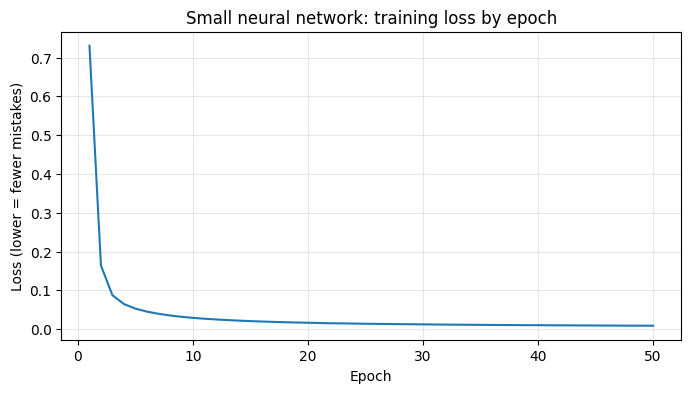

Loss after epoch 1:  0.7305
Loss after epoch 50: 0.0088


In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(small_net.loss_curve_) + 1), small_net.loss_curve_)
plt.title("Small neural network: training loss by epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss (lower = fewer mistakes)")
plt.grid(alpha=0.3)
plt.show()

print("Loss after epoch 1: ", round(small_net.loss_curve_[0], 4))
print("Loss after epoch 50:", round(small_net.loss_curve_[-1], 4))

**Observations:**

- The small network scores 99.82% on training songs and 99.78% on validation songs: essentially the same as logistic regression, and very slightly lower.
- Its loss fell from 0.7305 after the first epoch to 0.0088 after the fiftieth. Each epoch's weight adjustments made it a little less wrong, and the chart shows most of that improvement happened in the first few epochs.

## 6. Count the Weights

Let's look inside the model. A model's "knowledge" lives in its numbers: weights (one per connection) plus a starting offset for each output or neuron. Let's count them.

In [ ]:
# This function counts the numbers in a model's weights and offsets.
def count_parameters(model):
    if isinstance(model, LogisticRegression):
        return model.coef_.size + model.intercept_.size
    weights = sum(layer.size for layer in model.coefs_)
    offsets = sum(layer.size for layer in model.intercepts_)
    return weights + offsets

print("Logistic regression:", count_parameters(log_reg), "numbers")
print("Small neural network:", count_parameters(small_net), "numbers")

Logistic regression: 64 numbers
Small neural network: 324 numbers


When a model trains, all it does is adjust a set of numbers. When it finishes, those numbers are the model. There’s no stored list of songs or rules. Two kinds of numbers are involved:

- Weights: one per connection. A weight says how strongly one input pushes on one output. Large and positive pushes the output up, negative pushes it down, and near zero means it barely matters.
- Offsets: one per output or neuron. An offset is a starting value added before the inputs are counted, like a thumb on the scale. In machine learning these are usually called biases or intercepts.

Logistic regression gives us one number per feature for each mood, so we can read it. Here are its weights for the **Sad** mood, largest first.

In [ ]:
sad_row = list(log_reg.classes_).index("Sad")
sad_weights = pd.Series(log_reg.coef_[sad_row], index=X.columns).sort_values(key=abs, ascending=False)
sad_weights.round(2)

,0
energy,-9.19
acousticness,9.00
loudness,-7.52
danceability,-3.82
time_signature,-3.00
explicit,-2.76
tempo,-2.66
valence,-2.62
speechiness,-2.62
duration_ms,-1.98


Now let's try to read the neural network the same way. Here are the weights connecting each input to the first hidden neuron.

In [ ]:
first_neuron = pd.Series(small_net.coefs_[0][:, 0], index=X.columns)
first_neuron.round(2)

,0
popularity,-0.04
duration_ms,-0.05
explicit,-1.59
danceability,0.32
energy,0.28
key,0.05
loudness,0.59
mode,-0.04
speechiness,-0.32
acousticness,-0.58


**Observations:**

- Logistic regression stores 64 numbers: one weight per feature for each of the 4 moods (15 × 4 = 60), plus 4 offsets. The small network stores 324, about five times as many.
- Logistic regression's weights for Sad can be read: energy (−9.19) and acousticness (+9.00) are the largest, so lower energy and more acoustic sound push a song toward Sad. Loudness (−7.52) comes next.
- The neural network's weights for its first neuron are harder to read. Its largest is explicit (−1.59), but this neuron is only 1 of 16, and its output passes through another layer of weights before it reaches any mood. No single number tells us what the network "thinks" makes a song Sad.

## 7. Is Bigger Better?

Real-world neural networks have millions or billions of weights. Let's build a bigger one with **two hidden layers (128 neurons, then 64)** and compare. This one takes longer to train, usually under a minute.

In [ ]:
# Build a bigger network.  This one will have 128 neurons in the first hidden layer, then 64 in the second.
big_net = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=50, random_state=42)
big_net.fit(X_train, y_train)

results = pd.DataFrame({
    "model": ["Always guess Happy", "Logistic regression", "Small net (16)", "Big net (128, 64)"],
    "parameters": [0, count_parameters(log_reg), count_parameters(small_net), count_parameters(big_net)],
    "training accuracy": [None,
                          log_reg.score(X_train, y_train),
                          small_net.score(X_train, y_train),
                          big_net.score(X_train, y_train)],
    "validation accuracy": [(y_val == "Happy").mean(),
                            log_reg.score(X_val, y_val),
                            small_net.score(X_val, y_val),
                            big_net.score(X_val, y_val)],
})
results.round(4)

,model,parameters,training accuracy,validation accuracy
0,Always guess Happy,0,NaN,0.5668
1,Logistic regression,64,0.9985,0.9984
2,Small net (16),324,0.9982,0.9978
3,"Big net (128, 64)",10564,0.9988,0.9962


**Observations:**

- The big network has 10,564 parameters, about 165 times as many as logistic regression.
- It has the highest training accuracy (99.88%) but the lowest validation accuracy of the three models (99.62%). The extra weights helped it fit the training songs slightly better without helping on new songs.
- On this task, bigger was not necessarily better.

## 8. When Data Is Scarce

The lecture said deep networks "need lots of data." Let's test that. We'll train both models on only the first **50, 200, 1,000, and 5,000** training songs, then check each one on the full validation set.

In [ ]:
rows = []
for n in [50, 200, 1000, 5000]:
    lr = LogisticRegression(max_iter=1000).fit(X_train[:n], y_train[:n])
    nn = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500,
                       random_state=42).fit(X_train[:n], y_train[:n])
    for name, m in [("Logistic regression", lr), ("Big net (128, 64)", nn)]:
        rows.append({"training songs": n, "model": name,
                     "training accuracy": round(m.score(X_train[:n], y_train[:n]), 3),
                     "validation accuracy": round(m.score(X_val, y_val), 3)})

pd.DataFrame(rows)

,training songs,model,training accuracy,validation accuracy
0,50,Logistic regression,1.000,0.937
1,50,"Big net (128, 64)",1.000,0.889
2,200,Logistic regression,1.000,0.955
3,200,"Big net (128, 64)",1.000,0.950
4,1000,Logistic regression,0.995,0.983
5,1000,"Big net (128, 64)",1.000,0.978
6,5000,Logistic regression,0.995,0.995
7,5000,"Big net (128, 64)",1.000,0.988


**Observations:**

- With only 50 training songs, both models score 100% on those songs, but logistic regression gets 93.7% on validation while the big network gets 88.9%.
- The big network scores 100% on its training songs at every size, yet trails logistic regression on validation every time. That is memorizing: with 10,564 weights and only 50 songs, it has room to store the answers rather than learn the pattern.
- The gap shrinks as the data grows (88.9% vs. 93.7% at 50 songs, 98.8% vs. 99.5% at 5,000). Neural networks need lots of data to earn their extra weights.

## 9. Final Exam: The Test Set

We choose **logistic regression**. It matched the neural networks on validation, and it is far smaller and easier to explain. Now, once only, we check it on the test songs it has never seen.



*Bien -*

*I am also letting the big neural and small neural networks take this final exam.*

Test accuracy: 0.9978
Test accuracy: 0.9958
Test accuracy: 0.9975


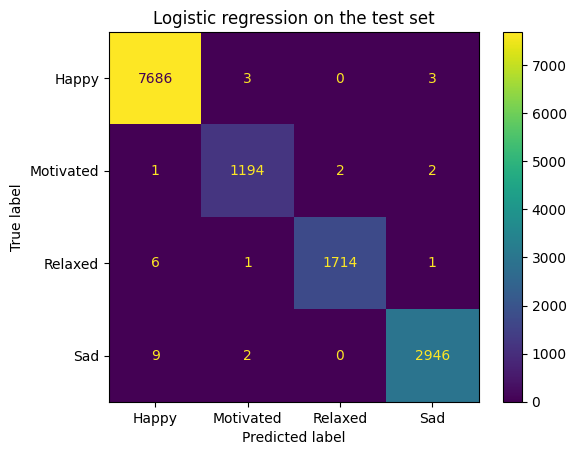

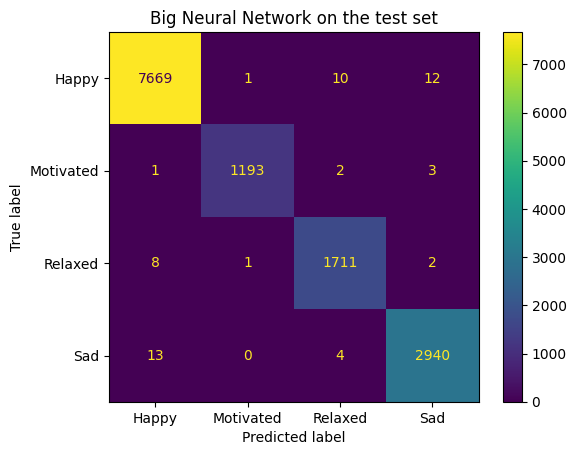

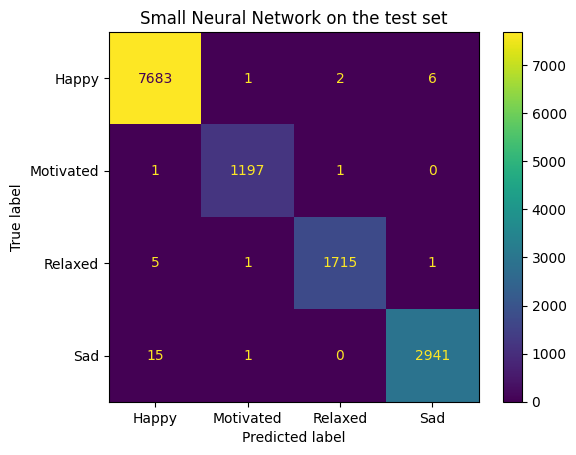

In [ ]:
print("Test accuracy:", round(log_reg.score(X_test, y_test), 4))
print("Test accuracy:", round(big_net.score(X_test, y_test), 4))
print("Test accuracy:", round(small_net.score(X_test, y_test), 4))

ConfusionMatrixDisplay.from_estimator(log_reg, X_test, y_test)
plt.title("Logistic regression on the test set")
plt.show()

ConfusionMatrixDisplay.from_estimator(big_net, X_test, y_test)
plt.title("Big Neural Network on the test set")
plt.show()

ConfusionMatrixDisplay.from_estimator(small_net, X_test, y_test)
plt.title("Small Neural Network on the test set")
plt.show()

**Observations:**

- Test accuracy is 99.78%, very close to the 99.84% validation score, so our validation estimate held up on songs the model had never seen.
- In the confusion matrix, each row is the true mood and each column is the predicted mood. Almost every song sits on the diagonal (correct).
- The largest mistakes: 9 Sad songs and 6 Relaxed songs were predicted as Happy.

## 10. Wait: Who Decided the Mood?

Accuracy this high should make us curious. Moods are human experiences, and two people can hear the same song differently. So where did these labels come from?

The dataset doesn't say. But we can look for clues. Here is the share of each mood among songs that are **not explicit (0)** and songs that **are explicit (1)**.

In [ ]:
pd.crosstab(songs_df["explicit"], songs_df["mood"], normalize="index").round(3)

mood,Happy,Motivated,Relaxed,Sad
explicit,,,,
0,0.62,0.004,0.138,0.238
1,0.00,0.989,0.007,0.004


**Observations:**

- Of the explicit songs, 98.9% are labeled Motivated. Of the non-explicit songs, only 0.4% are.
- Explicit lyrics don't make a song motivating. A pattern this sharp suggests the moods were not assigned by people listening to each song, but by a rule applied to the measurements, something like "if explicit, call it Motivated."
- That would explain our near-perfect accuracy. The model learned to copy whoever, or whatever, assigned the labels. It did not learn what a song feels like. A model can only be as true as the labels it learns from.

## 11. TODO: Reflection

Answer in 2–4 sentences each.

1. Logistic regression and the neural networks scored almost the same. If you were building this for a real music app, which would you choose, and why?

  *If I were building this for a real music app, I would use logistic regresssion. I tested out the big and small neural networks and they both performed almost as well as the logistic regression.  However, the mistakes that they made were significantly more numerous and worse in nature.  For a real music app, I am not as concerned with the AI predicting it to be motivated and it actually be happy, for example, but rather that the AI guess something and the opposite be true.  I pick logistic regression because it made only 15 opposite mistakes while the big neural network made 28 such mistakes and the small neural network made 21 such mistakes.*

2. In Section 6 you could read logistic regression's weights for "Sad," but not the neural network's. Why might that matter when an AI system makes decisions about people instead of songs?

  *This would matter because the neural network's logic is much more difficult to understand than for the logistic regression.  In the case of a crisis or even just a inspection of the AI model, it makes things difficult to diagnose the problem or change the AI model's logic.  Each neuron adds a level of complexity to the understanding of the AI models' learned traits.*

3. In Section 8 the big network scored 100% on its training songs but lower on new songs. What does that tell you about trusting a model's score on the data it was trained on?

  *This tells us that the big network works well at fitting itself to the data.  Rather than focusing solely on making connections that underly the data, the big network takes all data entries into more consideration, including outliers.  The big network's ability to account for specific outliers may lead to difficulty computing for different data with different outliers later on.*

4. The model learned the labels very well. Does that mean it learned what a "sad" or "happy" song really is? Explain using what you found in Section 10.

  *No, it does not know what a "sad" or "happy" song really is.  It just knows that certain variables are related in complex ways to a person (the one labeling each song's mood) choosing to pick one mood or another.  This data set gives broad, easily determined aspects of each song, but does not necessarily say which are causes, and which are effects.  For example, the AI doesn't know if the song is happy because it is danceable, or if the song is danceable because it is happy.  Section 10 said that,  "The model learned to copy whoever, or whatever, assigned the labels. It did not learn what a song feels like."  The AI models just predict, but do not comprehend, having never experienced happiness, sadness, motivation, or relaxation*